# Welcome to your first Jupyter Notebook

## Getting Started
Before working on this notebook make sure you have followed the instructions from the lab pdf.

You have upgraded pip

`python -m pip install --upgrade pip`

You installed ipykernel

`python -m pip install ipykernel`

You installed the Jupyter extension in VSCode.

Once those steps are finished, click in the top right where it says `Select Kernel` and then click on your Python version.

## Cells

A notebook is composed of two types of cells. **Code** and **Markdown**.

### Code Cells
**Code** cells are simply blocks of Python code. On the left of a **Code** cell will be a button that allows you to execute the cell. Try executing the cell below.

In [1]:
print("Hello world!")

Hello world!


You should see the output appear below the cell. The next thing you need to know is that the state is saved between each cell that is executed, just like if you were to have that code in a Python script.

In [2]:
message = "Hello world!"

After running the cell above, click the `Jupyter Variables` button on the top menu. You should see the `message` variable there.

Run the next cell.

In [3]:
print(message)

Hello world!


If you want to run every single **Code** cell in the notebook, you can click the button that says `Run All` located in the menu above VSCode's editor.

### Markdown Cells
**Markdown** cells are cells that format text. These allow you to document and explain what each part of your code is doing.

When in VSCode, you can edit a **Markdown** cell by double clicking on it.

In Markdown, you can add headings, **bold font**, *italics*, [links](https://www.markdownguide.org/basic-syntax/), and more. See the [documentation](https://www.markdownguide.org/basic-syntax/) for more information.

## Examples

For a more extensive example, we can take a look at what we did in Lab 8.

### Example 1 (from Lab 8)

**Step 1:** Start by running the cell below to import the modules we'll need. This is a very common first code cell for Jupyter notebooks.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
import pandas as pd

**Step 2:** Read in the data file with pandas and print it out (path may need to be changed)

In [2]:
path = ""
filename = "data.csv"
df = pd.read_csv(path+filename, header=None)
print(df)

   0     1
0  1   2.0
1  2   3.8
2  3   9.5
3  4   8.0
4  5  10.0
5  6  12.0


**Step 3:** Visualize data and get statistics

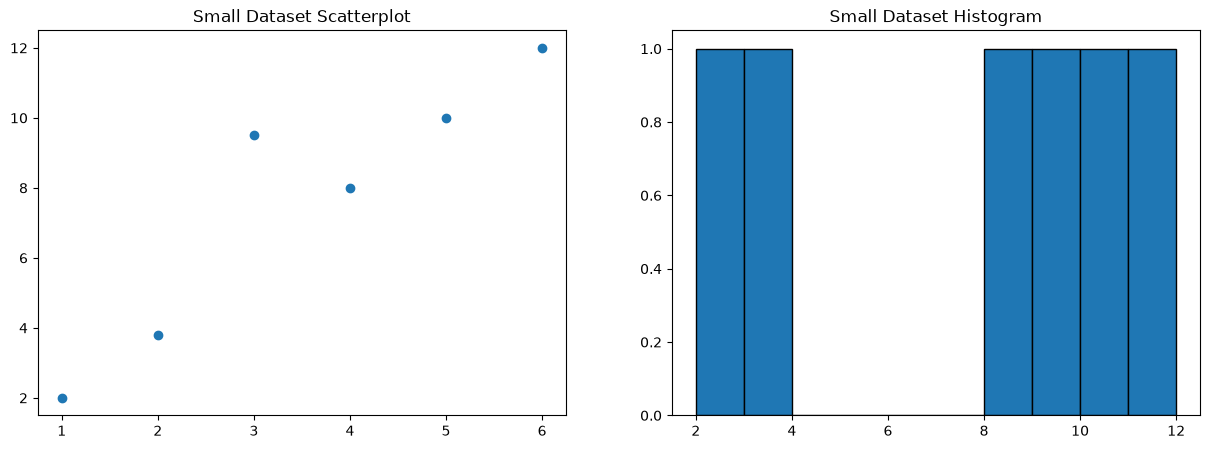

In [3]:
x = df[0]
y = df[1]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].scatter(x, y)
ax[0].set_title("Small Dataset Scatterplot")

ax[1].hist(df[1], edgecolor="black")
ax[1].set_title("Small Dataset Histogram")
plt.show()

Notice how we do not have to open a new window to see the plots.

In [4]:
print(df.describe())

              0          1
count  6.000000   6.000000
mean   3.500000   7.550000
std    1.870829   3.864583
min    1.000000   2.000000
25%    2.250000   4.850000
50%    3.500000   8.750000
75%    4.750000   9.875000
max    6.000000  12.000000


**Step 4:** Split the data into a set for testing and a set for training.

In [5]:
# convert to NumPy array
data_train = df[0:3].values
data_test = df[3:].values

# see the split
print(data_test)
print(data_train)

[[ 4.  8.]
 [ 5. 10.]
 [ 6. 12.]]
[[1.  2. ]
 [2.  3.8]
 [3.  9.5]]


**Step 5:** Split the x and y training sets and then reshape x to be in the right format for sklearn.

In [6]:
# split x,y & reshape x for sklearn
x_train = data_train[:,0].reshape(-1,1)
y_train = data_train[:,1]

# see the arrays
print(x_train,y_train)

[[1.]
 [2.]
 [3.]] [2.  3.8 9.5]


**Step 6:** Split the x and y testing sets and then reshape x to be in the right format for sklearn.

In [7]:
# split x,y and reshape x
x_test = data_test[:,0].reshape(-1,1)
y_test = data_test[:,1]

# see the arrays
print(x_test, y_test)

[[4.]
 [5.]
 [6.]] [ 8. 10. 12.]


**Step 7a:** Build the OLS model

In [8]:
model_ols = LinearRegression(fit_intercept=False).fit(x_train, y_train)

**Step 7b:** Build the Ridge Regression model

In [9]:
model_ridge = Ridge(alpha=5.0, fit_intercept=False).fit(x_train, y_train)

**Step 8:** Calculate and display MSE

In [10]:
# (8) calculate MSE: 
ols_mse = mean_squared_error(y_test, model_ols.predict(x_test))
ridge_mse = mean_squared_error(y_test, model_ridge.predict(x_test))

# display MSE for both
print(f"OLS slope:   {model_ols.coef_[0]:.2f} | Test MSE: {ols_mse:.2f}")
print(f"ridge slope: {model_ridge.coef_[0]:.2f} | Test MSE: {ridge_mse:.4f}")

OLS slope:   2.72 | Test MSE: 13.36
ridge slope: 2.01 | Test MSE: 0.0007


**Step 9:** Generate the graph

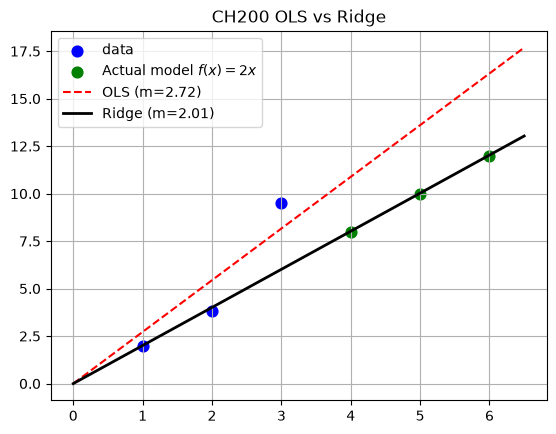

In [11]:
# abscissa for plotting
x_line = np.linspace(0, 6.5, 100).reshape(-1, 1)

# (9) matplotlib 
# plot points
plt.scatter(x_train, y_train, color='blue', s=60, label='data')
plt.scatter(x_test, y_test, color='green', s=60, label=r'Actual model $f(x)=2x$')

# plot lines
plt.plot(x_line, model_ols.predict(x_line), 'r--', label=f'OLS (m={model_ols.coef_[0]:.2f})')
plt.plot(x_line, model_ridge.predict(x_line), 'k-', linewidth=2, label=f'Ridge (m={model_ridge.coef_[0]:.2f})')
plt.legend()
plt.grid(True)
plt.title("CH200 OLS vs Ridge")
plt.show()

At the end of Lab 8, we changed the value of alpha. Now that we have our code in a notebook, we can just edit **Step 7b** and run the code after it. This allows us to skip the previous steps since those cells have already been ran.

### Example 2

Finish this example

Import modules

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score

Create test dataset

In [18]:
X = np.array([[1, 1], [1, 2], [2, 2], [2, 3]])
y = np.dot(X, np.array([1, 2])) + 3

**Build the model**

In [22]:
reg = LinearRegression(fit_intercept=False).fit(X,y)

Calculate and print the metrics $R^2$ and $\text{RMSE}$

In [23]:
ols_rmse = root_mean_squared_error(y, reg.predict(X))
ols_r2 = r2_score(y, reg.predict(X))

print(f"R^2: {ols_r2}")
print(f"RMSE {ols_rmse}")

R^2: 0.7482517482517483
RMSE 0.9045340337332909
